# Livrable 2 — Étude comparative approfondie des objets routiers
## Préparation des données, sélection de variables, apprentissage et analyse critique

**Projet PACTE — HESTIM.** À partir d'une image recadrée contenant un objet principal,
prédire l'une des classes `bus`, `car`, `cyclist`, `motorcycle` ou `pedestrian`.
Conformément au guide d'annotation, `cyclist` inclut les vélos seuls ou avec cycliste et
`motorcycle` inclut les motos et scooters.

**Question étudiée :** quel compromis entre représentation de l'image, sélection des variables,
correction du déséquilibre, famille d'algorithmes et coût de calcul donne les résultats les plus
convaincants sur nos données ?

Cette étude élargit le deuxième livrable à **10 modèles couvrant plusieurs familles**, **60 configurations
initiales**, deux références triviales, une recherche ciblée sur validation croisée par groupes,
une ablation des descripteurs, une courbe d'apprentissage et une analyse de l'incertitude.
Les conclusions s'appuient sur les résultats calculés ; multiplier les essais ne garantit
ni une amélioration ni la robustesse à des images externes.

**Lecture :** exécuter les cellules dans l'ordre. Les résultats réels sont rechargés par défaut.
`RUN_EXPERIMENTS = True` relance l'ensemble de l'étude et peut prendre plusieurs minutes.
Le code réutilisable se trouve dans `backend/livrable2.py` et `backend/ml_pipeline.py`.
Les originaux ne sont jamais modifiés. Ce notebook prolonge `Nettoyage_des_donnees.ipynb`.

## 1. Environnement et reproductibilité

La cellule repère la racine depuis le projet ou son dossier `notebooks`, charge les outils et fixe
une graine à 42. Les versions sont affichées pour documenter l'environnement. Les dépendances
figurent dans `backend/requirements.txt` ; les images sont déjà disponibles localement.
Les résultats de l'étude sont enregistrés dans `backend/models/livrable2/`.

In [1]:
from pathlib import Path
import importlib.metadata
import inspect
import json
import platform
import sys

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'dataset/train').is_dir() and (p / 'backend/ml_pipeline.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Ouvrir le notebook dans le dossier MLProject ou notebooks.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from backend.ml_pipeline import CLASSES, extract_features, load_pixels
from backend.livrable2 import make_pipeline, run_experiments, training_sample
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import Image as DisplayImage, Markdown, display

if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
SEED = 42
RUN_EXPERIMENTS = False
OUT = ROOT / 'backend/models/livrable2'
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 65)
print('Python :', platform.python_version(), '— graine :', SEED)
display(pd.DataFrame([{'bibliotheque': name, 'version': importlib.metadata.version(name)}
                     for name in ['numpy', 'pandas', 'scikit-learn', 'scikit-image', 'Pillow', 'matplotlib']]))

Python : 3.14.2 — graine : 42


,bibliotheque,version
0,numpy,2.4.2
1,pandas,2.3.3
2,scikit-learn,1.9.1
3,scikit-image,0.26.0
4,Pillow,12.2.0
5,matplotlib,3.10.8


## 2. Chargement, qualité et analyse descriptive

`sources.csv` relie chaque image à sa classe, son split et sa provenance. Nous recalculons les
effectifs et la distribution des sources pour repérer les écarts possibles de domaine. Les champs
indispensables sont contrôlés ; une licence manquante n'est pas une valeur numérique à imputer.
La provenance sert à contrôler l'évaluation, sans devenir une variable prédictive.

La cellule affiche les effectifs initiaux et vérifie l'absence de chemins répétés ou de champs
obligatoires vides. La revue des étiquettes reste partielle : ces contrôles ne prouvent pas que
toutes les annotations sont exactes.

In [2]:
metadata = pd.read_csv(ROOT / 'dataset/sources.csv', keep_default_na=False)
original = metadata[metadata['split'].isin(['train', 'validation', 'test'])].copy()
required = ['image', 'class', 'split', 'source_group', 'pixel_sha256', 'source']
assert not original[required].eq('').any().any(), 'Champ indispensable vide.'
assert not original['image'].duplicated().any(), 'Chemin répété.'
display(original.groupby(['class', 'split']).size().unstack(fill_value=0).reindex(CLASSES))
display(pd.crosstab(original['source'], original['split']))
print('Images référencées :', len(original))
print('Groupes source :', original['source_group'].nunique())

split,test,train
class,,
bus,200,800
car,200,800
cyclist,200,800
motorcycle,200,800
pedestrian,200,800


split,test,train
source,,
coco,304,1378
kaggle,358,1656
original,194,710
penn_fudan,144,256


Images référencées : 5000
Groupes source : 3623


## 3. Protocole expérimental et prévention des fuites de données

L'audit relit les images, vérifie les empreintes de pixels et écarte en mémoire les fichiers
illisibles et les doublons exacts. Les quasi-doublons pHash ne sont pas supprimés : leurs groupes
sont réunis par prudence. Un rapprochement entre splits entraîne un arrêt pour revue.

La validation initiale est extraite du train en conservant ensemble les `source_group` et les
groupes apparentés. Parmi 1 024 propositions reproductibles, la règle retient la partition
dont les effectifs sont les plus proches de la cible de 15 %, avec un support minimal par classe.
**Aucun score de modèle n'intervient dans le choix de cette séparation.**

### Une étude en plusieurs étapes

| Étape | Objectif | Données utilisées pour les décisions |
|---|---|---|
| Référence triviale | Mesurer ce qu'obtient une prédiction majoritaire | Train et validation initiale |
| Comparaison large | 10 modèles × 3 sélections × 2 stratégies = 60 configurations | Même validation groupée pour tous |
| Recherche ciblée | Comparer un petit ensemble de paramètres pour les trois modèles présélectionnés | Validation croisée à 3 plis, sans séparation des groupes |
| Diagnostics | Étudier les descripteurs, le volume d'apprentissage et le coût | Développement uniquement |
| Évaluation finale | Décrire les dix finalistes et le modèle retenu | Test existant après gel des choix |

Les transformations et les sélections de variables sont réajustées dans chaque entraînement.
Les duplications éventuelles concernent seulement ses exemples d'apprentissage.
Le test n'est jamais rééquilibré et n'intervient pas dans le choix des configurations.

**Limite de sélection :** la présélection et la recherche ciblée réutilisent des données de
développement. La validation croisée sert au choix du modèle ; ce n'est pas une évaluation
imbriquée indépendante de l'ensemble du processus.

**Historique du test :** ce jeu a déjà été évalué dans le projet. Les nouveaux scores sont
des mesures sur ce test existant, pas une confirmation sur un jeu encore inconnu.
Une confirmation indépendante nécessiterait des images externes réservées à l'avance.

La cellule suivante vérifie la version du protocole avant de recharger les résultats. Si les
résultats manquent ou correspondent à l'ancienne étude, elle lance les nouveaux calculs.

In [3]:
metrics_path = OUT / 'evaluation_metrics.json'
saved = json.loads(metrics_path.read_text(encoding='utf-8')) if metrics_path.is_file() else {}
status_path = OUT / 'run_status.json'
status = json.loads(status_path.read_text(encoding='utf-8')) if status_path.is_file() else {}
current = (saved.get('protocol_version') == 'expanded-v2' and saved.get('run_status') == 'complete'
           and status.get('protocol_version') == 'expanded-v2' and status.get('status') == 'complete')
if status.get('protocol_version') == 'expanded-v2' and status.get('status') != 'complete' and not RUN_EXPERIMENTS:
    raise RuntimeError('Calcul en cours ou interrompu : attendre sa fin ; pour relancer explicitement, utiliser RUN_EXPERIMENTS = True.')
if RUN_EXPERIMENTS or not current:
    results = run_experiments(ROOT, output_dir=OUT, seed=SEED)
else:
    results = saved
    print('Résultats rechargés — exécution UTC :', results['timestamp_utc'])
manifest = pd.read_csv(OUT / 'split_manifest.csv', keep_default_na=False)
audit = json.loads((OUT / 'quality_audit.json').read_text(encoding='utf-8'))
comparison = pd.read_csv(OUT / 'validation_results.csv')
decision = results['selection']
winner = decision['winner']
assert len(comparison) == results['benchmark_count'] == 60
assert comparison['model'].nunique() == 10
assert manifest.groupby('evaluation_group')['split'].nunique().max() == 1
print('Images conservées :', audit['retained_images'])
print('Exclusions automatiques :', len(audit['excluded']))
print('Paires similaires signalées :', len(audit['near_pairs']))
print('Groupes partagés entre splits :', results['split_summary']['group_overlap'])
print('Configurations initiales :', len(comparison))
display(pd.DataFrame(audit['near_pairs']))

Résultats rechargés — exécution UTC : 2026-11-25T21:30:09.664696+00:00
Images conservées : 5000
Exclusions automatiques : 0
Paires similaires signalées : 3
Groupes partagés entre splits : 0
Configurations initiales : 60


,image_a,image_b,distance
0,test/pedestrian/kg_train_243451.png,test/pedestrian/kg_val_51808.png,4
1,train/cyclist/kg_train_298230.png,train/cyclist/kg_train_298885.png,4
2,train/pedestrian/kg_train_280574.png,train/pedestrian/kg_val_59832.png,4


### 3.1. Répartition obtenue et échantillons réels

La cellule affiche les effectifs effectivement utilisés et trois exemples par classe.
Les grands groupes de piétons empêchent d'obtenir exactement 15 % par classe sans les couper.
L'indépendance des groupes est prioritaire sur une stratification exacte. Les exemples servent
à observer les recadrages et les étiquettes, sans remplacer une vérification exhaustive.

split,train,validation,test
class,,,
bus,680,120,200
car,680,120,200
cyclist,681,119,200
motorcycle,677,123,200
pedestrian,544,256,200


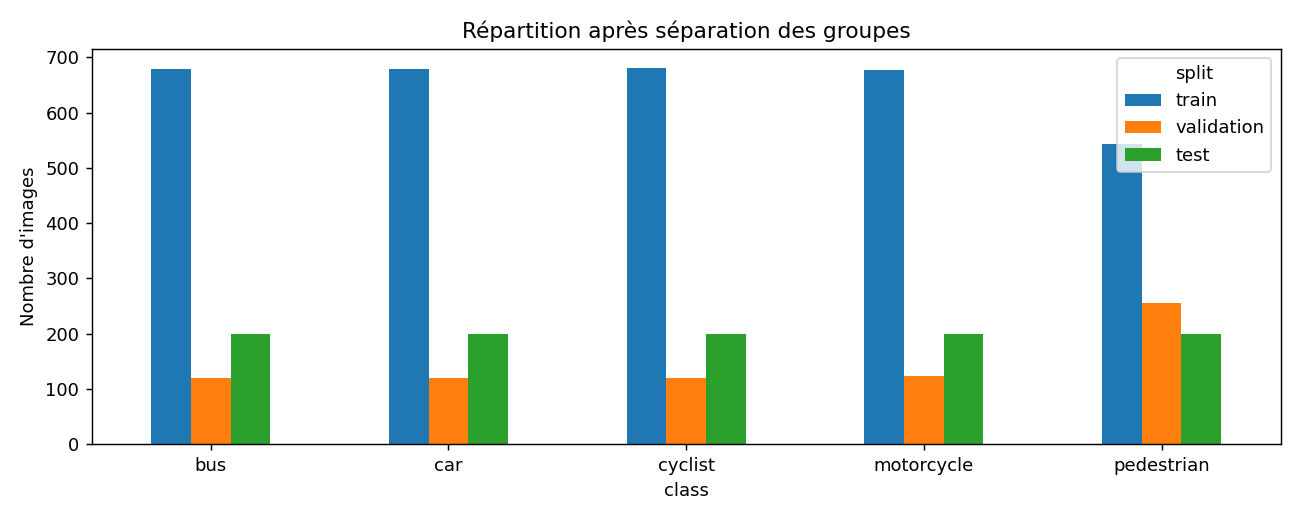

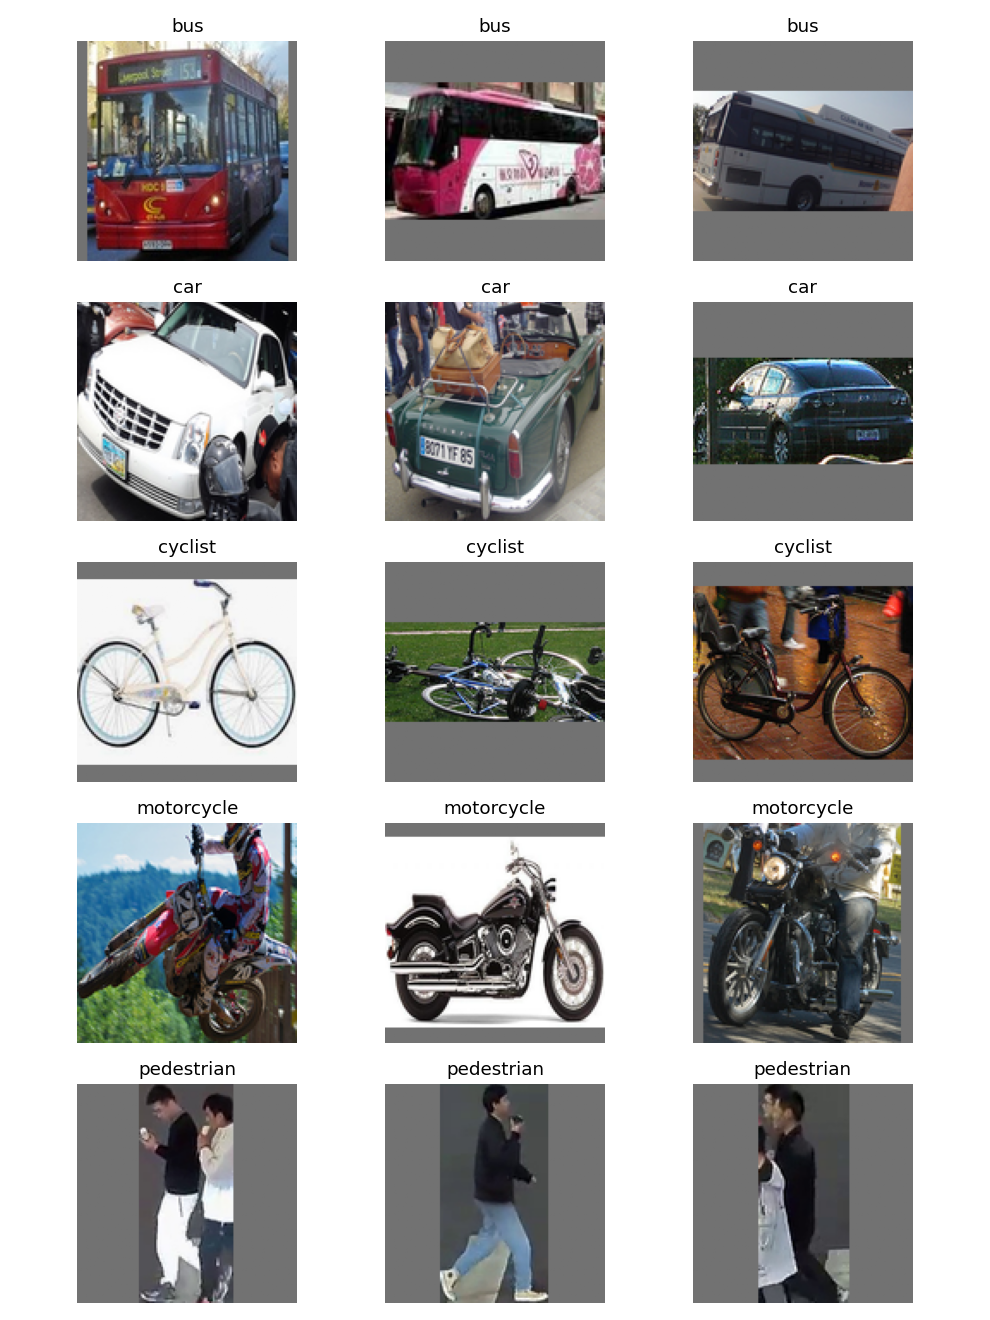

La validation initiale contient **738 images**, soit **18.45%** du développement. Cette séparation est identique pour les **60 configurations initiales**.

In [4]:
counts = pd.crosstab(manifest['class'], manifest['split']).reindex(CLASSES)[['train', 'validation', 'test']]
display(counts)
display(DisplayImage(filename=str(OUT / 'figures/class_distribution.png')))
display(DisplayImage(filename=str(OUT / 'figures/sample_images.png')))
display(Markdown(f"La validation initiale contient **{counts['validation'].sum()} images**, soit "
                 f"**{results['split_summary']['actual_validation_fraction']:.2%}** du développement. "
                 f"Cette séparation est identique pour les **{len(comparison)} configurations initiales**."))

## 4. Préparation numérique et analyse des caractéristiques

Les images sont converties en RGB, mises au format 128 × 128 en conservant leurs proportions
avec des marges grises si nécessaire, puis leurs pixels sont divisés par 255.

- **HOG : 1 764 valeurs** pour décrire les contours et les formes sur l'image grise.
- **Histogrammes HSV : 96 valeurs**, soit 32 intervalles par canal pour décrire les couleurs.
- **Total : 1 860 caractéristiques** par image. L'extraction utilise une configuration fixe,
  sans apprendre sur les étiquettes.

La cellule vérifie le vecteur d'un exemple et calcule des statistiques sur un échantillon
reproductible de 10 images par classe, pris uniquement dans le train interne.
Ces statistiques sont descriptives et ne servent pas à choisir les variables.

,descripteur,variables,moyenne,ecart_type,minimum,maximum
0,HOG,1764,0.117695,0.111435,0.0,0.830254
1,HSV,96,0.031250,0.077478,0.0,0.997314


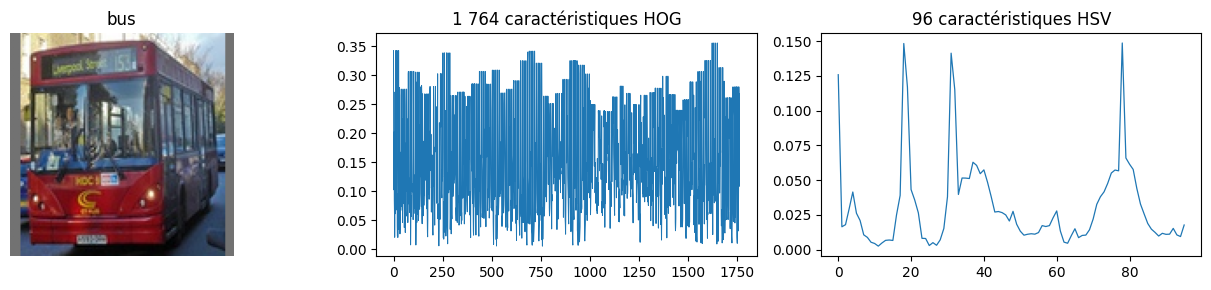

In [5]:
sample = manifest[manifest['split'].eq('train')].groupby('class', group_keys=False).sample(n=10, random_state=SEED)
sample_x = np.stack([extract_features(ROOT / 'dataset' / name) for name in sample['image']])
example = sample.iloc[0]
pixels = load_pixels(ROOT / 'dataset' / example['image'])
assert sample_x.shape == (50, 1860) and np.isfinite(sample_x).all()
assert pixels.shape == (128, 128, 3) and 0 <= pixels.min() <= pixels.max() <= 1
descriptive = pd.DataFrame([
    {'descripteur': name, 'variables': block.shape[1], 'moyenne': float(block.mean()),
     'ecart_type': float(block.std()), 'minimum': float(block.min()), 'maximum': float(block.max())}
    for name, block in [('HOG', sample_x[:, :1764]), ('HSV', sample_x[:, 1764:])]
])
display(descriptive)
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
axes[0].imshow(pixels)
axes[0].set_title(str(example['class']))
axes[0].axis('off')
axes[1].plot(sample_x[0, :1764], linewidth=0.7)
axes[1].set_title('1 764 caractéristiques HOG')
axes[2].plot(sample_x[0, 1764:], linewidth=0.9)
axes[2].set_title('96 caractéristiques HSV')
fig.tight_layout()
fig.savefig(OUT / 'figures/feature_example.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Gestion du déséquilibre

Les données initiales ont le même nombre d'images par classe. La séparation groupée crée un
déséquilibre modéré dans le train interne. La correction est une hypothèse à comparer avec une
référence sans correction, plutôt qu'une amélioration supposée.

Pour **SVM, SGD, régression logistique, Random Forest, Extra Trees et arbre de décision**, la
correction donne davantage de poids aux exemples des classes minoritaires. La règle équilibrée
utilise **w_c = N / (K × n_c)** sur les données d'ajustement.

Pour **k-NN, Gaussian Naive Bayes, HistGradientBoosting et MLP**, la correction utilise un
suréchantillonnage aléatoire : on duplique des lignes du train jusqu'à atteindre l'effectif
de sa classe majoritaire. HistGradientBoosting accepte aussi des poids, mais la construction
pondérée de ses intervalles s'est révélée coûteuse dans cet environnement. Nous retenons donc
pour lui le même suréchantillonnage que pour ces trois autres modèles. Ce choix de calcul
est documenté, sans supposer qu'il est équivalent à une pondération.

Le catalogue précise le mécanisme effectivement appliqué à chaque modèle.

La validation et le test ne sont jamais rééquilibrés. Aucun fichier image n'est dupliqué.
Le suréchantillonnage peut augmenter le surapprentissage et n'apporte aucune information nouvelle.
La forêt de sélection est pondérée dans les deux modalités pour conserver la même méthode
de sélection lorsque l'on compare la correction du classifieur.

La cellule affiche les effectifs, les poids du train interne et le code de rééchantillonnage.

In [6]:
balancing = pd.read_csv(OUT / 'balancing_details.csv')
display(balancing)
print('Rapport classe majoritaire / minoritaire :', round(balancing['train_count'].max() / balancing['train_count'].min(), 3))
display(Markdown('```python\n' + inspect.getsource(training_sample) + '\n```'))

,class,train_count,class_weight,oversampled_train_count
0,bus,680,0.959412,681
1,car,680,0.959412,681
2,cyclist,681,0.958003,681
3,motorcycle,677,0.963663,681
4,pedestrian,544,1.199265,681


Rapport classe majoritaire / minoritaire : 1.252


```python
def training_sample(x, y, model, balancing, seed=42):
    """Duplication du train selon la stratégie retenue pour chaque modèle."""
    if model not in RESAMPLED_MODELS or balancing != "Correction_train":
        return x, y
    rng = np.random.default_rng(seed)
    labels, counts = np.unique(y, return_counts=True)
    indices = [np.arange(len(y))]
    for label, count in zip(labels, counts):
        if count < counts.max():
            indices.append(rng.choice(np.flatnonzero(y == label), int(counts.max() - count), replace=True))
    indices = np.concatenate(indices)
    return x[indices], y[indices]

```

## 6. Sélection des variables et diversité des modèles

### 6.1. Trois méthodes de sélection

Une image est décrite par **1 860 composantes HOG et HSV** : ce sont les variables étudiées.
Les indices retenus sont enregistrés pour chaque expérience.

1. **Toutes** : référence conservant toutes les variables non constantes.
2. **ANOVA 50 %** : filtre supervisé qui retient la moitié des variables ayant les meilleurs scores
   F entre classes. Il est rapide mais étudie chaque variable séparément. Les scores servent
   au classement ; ils ne sont pas interprétés ici comme une preuve statistique ou causale.
3. **Importance RF 50 %** : méthode embarquée utilisant une forêt de 100 arbres pour retenir
   la moitié des variables les plus importantes. Elle peut exploiter des interactions, mais
   l'importance peut se répartir entre variables corrélées.

`VarianceThreshold` retire les constantes ; `StandardScaler` apprend ses paramètres uniquement
sur les données d'ajustement ; la sélection et le classifieur sont dans la même pipeline.
La PCA créerait de nouvelles composantes : elle ne remplace pas une comparaison de sélections
des variables d'origine dans cette étude.

La cellule affiche le code de construction et les nombres de variables retenues. La liste
détaillée des indices est dans `selected_features_validation.csv`.

In [7]:
display(Markdown('```python\n' + inspect.getsource(make_pipeline) + '\n```'))
variables = pd.read_csv(OUT / 'selected_features_validation.csv')
variable_counts = variables.groupby(['selection', 'model', 'balancing', 'descriptor']).size().unstack(fill_value=0)
display(variable_counts)

```python
def make_pipeline(selection, model, balancing, seed=42, parameters=None,
                  descriptor="HOG_HSV", memory=None):
    """Descripteurs fixes, puis transformations et sélection ajustées sur le train."""
    if selection not in SELECTIONS or model not in MODELS or balancing not in BALANCING:
        raise ValueError("Configuration d'expérience inconnue.")
    blocks = {"HOG_HSV": list(range(1860)), "HOG": list(range(1764)),
              "HSV": list(range(1764, 1860))}
    if descriptor not in blocks:
        raise ValueError("Descripteur inconnu.")
    selectors = {
        "Toutes": "passthrough",
        "ANOVA_50pct": SelectPercentile(f_classif, percentile=50),
        "Importance_RF_50pct": SelectFromModel(
            RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                   random_state=seed, n_jobs=4),
            threshold=-np.inf, max_features=_half_features,
        ),
    }
    weight = "balanced" if balancing == "Correction_train" else None
    estimators = {
        "SVM": SVC(C=10, kernel="rbf", class_weight=weight, random_state=seed, cache_size=512),
        "SGD": SGDClassifier(loss="hinge", alpha=0.0001, class_weight=weight,
                              random_state=seed, max_iter=2000, tol=1e-3),
        "LogisticRegression": LogisticRegression(C=1, class_weight=weight, max_iter=1500),
        "RandomForest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                               class_weight=weight, random_state=seed, n_jobs=4),
        "ExtraTrees": ExtraTreesClassifier(n_estimators=200, min_samples_leaf=2,
                                           class_weight=weight, random_state=seed, n_jobs=4),
        "kNN": KNeighborsClassifier(n_neighbors=5, weights="distance", n_jobs=4),
        "DecisionTree": DecisionTreeClassifier(max_depth=15, min_samples_leaf=3,
                                               class_weight=weight, random_state=seed),
        "GaussianNB": GaussianNB(var_smoothing=1e-9),
        # Pas de validation interne aléatoire qui ignorerait les groupes source.
        "HistGradientBoosting": HistGradientBoostingClassifier(
            max_iter=100, max_leaf_nodes=15, l2_regularization=1, class_weight=None,
            early_stopping=False, random_state=seed),
        "MLP": MLPClassifier(hidden_layer_sizes=(96,), alpha=0.001, batch_size=128,
                             max_iter=180, tol=1e-3, n_iter_no_change=15,
                             early_stopping=False, random_state=seed),
    }
    estimator = estimators[model]
    if parameters:
        estimator.set_params(**parameters)
    return Pipeline([
        ("descriptor", ColumnTransformer([("block", "passthrough", blocks[descriptor])],
                                          remainder="drop")),
        ("variance", VarianceThreshold()),
        ("scaler", StandardScaler()),
        ("selection", selectors[selection]),
        ("model", estimator),
    ], memory=memory)

```

descriptor                                                  HOG  HSV
selection           model                balancing                  
ANOVA_50pct         DecisionTree         Correction_train   926    4
                                         Sans_correction    926    4
                    ExtraTrees           Correction_train   926    4
                                         Sans_correction    926    4
                    GaussianNB           Correction_train   926    4
                                         Sans_correction    926    4
                    HistGradientBoosting Correction_train   926    4
                                         Sans_correction    926    4
                    LogisticRegression   Correction_train   926    4
                                         Sans_correction    926    4
                    MLP                  Correction_train   926    4
                                         Sans_correction    926    4
                    RandomForest         Correction_train   926    4
                                         Sans_correction    926    4
                    SGD                  Correction_train   926    4
                                         Sans_correction    926    4
                    SVM                  Correction_train   926    4
                                         Sans_correction    926    4
                    kNN                  Correction_train   926    4
                                         Sans_correction    926    4
Importance_RF_50pct DecisionTree         Correction_train   860   70
                                         Sans_correction    860   70
                    ExtraTrees           Correction_train   860   70
                                         Sans_correction    860   70
                    GaussianNB           Correction_train   865   65
                                         Sans_correction    860   70
                    HistGradientBoosting Correction_train   865   65
                                         Sans_correction    860   70
                    LogisticRegression   Correction_train   860   70
                                         Sans_correction    860   70
                    MLP                  Correction_train   865   65
                                         Sans_correction    860   70
                    RandomForest         Correction_train   860   70
                                         Sans_correction    860   70
                    SGD                  Correction_train   860   70
                                         Sans_correction    860   70
                    SVM                  Correction_train   860   70
                                         Sans_correction    860   70
                    kNN                  Correction_train   865   65
                                         Sans_correction    860   70
Toutes              DecisionTree         Correction_train  1764   96
                                         Sans_correction   1764   96
                    ExtraTrees           Correction_train  1764   96
                                         Sans_correction   1764   96
                    GaussianNB           Correction_train  1764   96
                                         Sans_correction   1764   96
                    HistGradientBoosting Correction_train  1764   96
                                         Sans_correction   1764   96
                    LogisticRegression   Correction_train  1764   96
                                         Sans_correction   1764   96
                    MLP                  Correction_train  1764   96
                                         Sans_correction   1764   96
                    RandomForest         Correction_train  1764   96
                                         Sans_correction   1764   96
                    SGD                  Correction_train  1764   96
                                         Sans_correction   1764   9

### 6.2. Dix modèles de classification et deux références triviales

La diversité des algorithmes permet de comparer des hypothèses différentes sur les données.
Les modèles suivants reçoivent les mêmes descripteurs et la même séparation initiale.

| Modèle | Principe | Ce que la comparaison permet d'étudier |
|---|---|---|
| SVM RBF | Frontières non linéaires à marge | Séparation souple dans l'espace HOG/HSV |
| Classifieur linéaire SGD | Frontières à marge ajustées par gradient stochastique | Référence linéaire efficace face au SVM RBF |
| Régression logistique | Modèle linéaire discriminant | Référence linéaire et régularisée |
| Random Forest | Agrégation d'arbres aléatoires | Interactions et variance réduite par l'ensemble |
| Extra Trees | Ensemble d'arbres avec des coupures plus aléatoires | Effet d'une randomisation différente de celle de RF |
| k-NN | Vote des exemples proches | Pertinence de la proximité et sensibilité à la dimension |
| Arbre de décision | Règles successives de séparation | Référence simple et risque de surapprentissage |
| Gaussian Naive Bayes | Distributions conditionnelles gaussiennes, indépendance supposée | Référence probabiliste peu coûteuse |
| Gradient boosting par histogrammes | Arbres construits successivement | Correction progressive des erreurs |
| Perceptron multicouche, MLP | Réseau de neurones sur les caractéristiques | Frontières non linéaires apprises par un réseau dense |

Deux références **DummyClassifier**, majoritaire et aléatoire stratifiée, n'apprennent pas de
relation image/classe : elles fournissent des points de comparaison minimaux. Le MLP utilise les caractéristiques classiques ; ce n'est pas
un réseau convolutif entraîné directement sur les pixels.

La cellule affiche le catalogue effectivement exécuté, y compris le mécanisme de correction
du déséquilibre. Les noms et paramètres réels sont également enregistrés dans les résultats.

In [8]:
catalog = pd.DataFrame(results['model_catalog'])
display(catalog)
assert set(comparison['model']) == set(catalog['model'])
display(Markdown(f"**{comparison['model'].nunique()} modèles**, chacune comparée avec trois sélections "
                 'et deux stratégies de gestion du déséquilibre, plus une référence majoritaire.'))

,model,principle,balancing
0,SVM,"Frontières non linéaires, noyau RBF",Poids de classes calculés sur le train
1,SGD,"Séparateur linéaire à marge, descente de gradi...",Poids de classes calculés sur le train
2,LogisticRegression,Régression logistique multiclasse,Poids de classes calculés sur le train
3,RandomForest,Vote d'arbres ajustés sur échantillons bootstrap,Poids de classes calculés sur le train
4,ExtraTrees,Ensemble d'arbres avec seuils aléatoires,Poids de classes calculés sur le train
5,kNN,Vote des cinq voisins pondéré par distance,Suréchantillonnage du train en mémoire
6,DecisionTree,Règles de décision hiérarchiques,Poids de classes calculés sur le train
7,GaussianNB,Modèle bayésien naïf gaussien,Suréchantillonnage du train en mémoire
8,HistGradientBoosting,Arbres construits par boosting sur histogrammes,Suréchantillonnage du train en mémoire
9,MLP,"Réseau de neurones dense, une couche cachée",Suréchantillonnage du train en mémoire


**10 modèles**, chacune comparée avec trois sélections et deux stratégies de gestion du déséquilibre, plus une référence majoritaire.

## 7. Comparaison large : 60 configurations sur une validation commune

Le **F1 macro** donne le même poids aux cinq classes. Il sert à présélectionner les modèles,
avec l'accuracy et les scores pondérés comme mesures complémentaires. Les scores train portent
sur les images originales du train interne, même si l'ajustement utilise des lignes dupliquées.

La cellule classe les 60 configurations et affiche une carte de leurs scores. Le tableau complet
conserve aussi les durées et les écarts train/validation. Le meilleur score de cette étape est
un résultat de présélection, pas encore le choix final de la recherche ciblée.

,selection,model,balancing,n_features,train_accuracy,train_f1_macro,validation_accuracy,validation_precision_weighted,validation_recall_weighted,validation_f1_macro,validation_f1_weighted,validation_balanced_accuracy,validation_mcc,validation_predict_seconds,fit_seconds,fit_samples,convergence_warning,warnings,iterations,ecart_f1_train_validation
0,Toutes,SVM,Sans_correction,1860,1.0000,1.0000,0.8360,0.8539,0.8360,0.8251,0.8408,0.8346,0.7930,3.3836,6.572,3262,False,NaN,2032.0,0.1749
1,Toutes,SVM,Correction_train,1860,1.0000,1.0000,0.8360,0.8539,0.8360,0.8251,0.8408,0.8346,0.7930,1.8564,5.894,3262,False,NaN,2032.0,0.1749
2,ANOVA_50pct,SVM,Sans_correction,930,1.0000,1.0000,0.8320,0.8445,0.8320,0.8202,0.8354,0.8294,0.7867,0.8050,1.471,3262,False,NaN,2272.0,0.1798
3,ANOVA_50pct,SVM,Correction_train,930,1.0000,1.0000,0.8306,0.8437,0.8306,0.8192,0.8341,0.8287,0.7851,0.8210,1.583,3262,False,NaN,2272.0,0.1808
4,Toutes,HistGradientBoosting,Sans_correction,1860,1.0000,1.0000,0.8306,0.8410,0.8306,0.8168,0.8328,0.8252,0.7844,0.0470,53.101,3262,False,NaN,100.0,0.1832
5,Toutes,MLP,Correction_train,1860,1.0000,1.0000,0.8225,0.8403,0.8225,0.8083,0.8273,0.8180,0.7757,0.0128,4.680,3405,False,NaN,30.0,0.1917
6,Toutes,MLP,Sans_correction,1860,1.0000,1.0000,0.8211,0.8395,0.8211,0.8081,0.8261,0.8171,0.7739,0.0130,4.677,3262,False,NaN,30.0,0.1919
7,Importance_RF_50pct,SVM,Sans_correction,930,1.0000,1.0000,0.8184,0.8403,0.8184,0.8080,0.8240,0.8174,0.7714,0.7996,3.253,3262,False,NaN,2107.0,0.1920
8,Importance_RF_50pct,SVM,Correction_train,930,1.0000,1.0000,0.8184,0.8403,0.8184,0.8080,0.8240,0.8174,0.7714,1.4851,1.485,3262,False,NaN,2107.0,0.1920
9,Importance_RF_50pct,HistGradientBoosting,Sans_correction,930,1.0000,1.0000,0.8198,0.8338,0.8198,0.8068,0.8233,0.8170,0.7716,0.0810,27.135,3262,False,NaN,100.0,0.1932


Référence majoritaire — F1 macro validation : 0.0555


,stage,strategy,accuracy,f1_macro
0,validation,most_frequent,0.1612,0.0555
1,validation,stratified,0.1951,0.1891
2,test,most_frequent,0.2000,0.0667
3,test,stratified,0.2160,0.2157


model                                 DecisionTree  ExtraTrees  GaussianNB  \
selection           balancing                                                
ANOVA_50pct         Correction_train        0.6068      0.7978      0.7305   
                    Sans_correction         0.6053      0.8028      0.7397   
Importance_RF_50pct Correction_train        0.5914      0.7806      0.7730   
                    Sans_correction         0.5999      0.7874      0.7668   
Toutes              Correction_train        0.5667      0.8025      0.7530   
                    Sans_correction         0.5627      0.7988      0.7499   

model                                 HistGradientBoosting  \
selection           balancing                                
ANOVA_50pct         Correction_train                0.8060   
                    Sans_correction                 0.8068   
Importance_RF_50pct Correction_train                0.8020   
                    Sans_correction                 0.8068   
Toutes              Correction_train                0.8030   
                    Sans_correction                 0.8168   

model                                 LogisticRegression     MLP  \
selection           balancing                                      
ANOVA_50pct         Correction_train              0.7450  0.7863   
                    Sans_correction               0.7433  0.7919   
Importance_RF_50pct Correction_train              0.7374  0.7842   
                    Sans_correction               0.7362  0.7896   
Toutes              Correction_train              0.7579  0.8083   
                    Sans_correction               0.7563  0.8081   

model                                 RandomForest     SGD     SVM     kNN  
selection           balancing                                               
ANOVA_50pct         Correction_train        0.8007  0.7322  0.8192  0.6944  
                    Sans_correction         0.7957  0.7467  0.8202  0.6831  
Importance_RF_50pct Correction_train        0.7956  0.7381  0.8080  0.6854  
                    Sans_correction         0.7842  0.7361  0.8080  0.6734  
Toutes              Correction_train        0.8011  0.7824  0.8251  0.6742  
                    Sans_correction         0.8057  0.7786  0.8251  0.6678

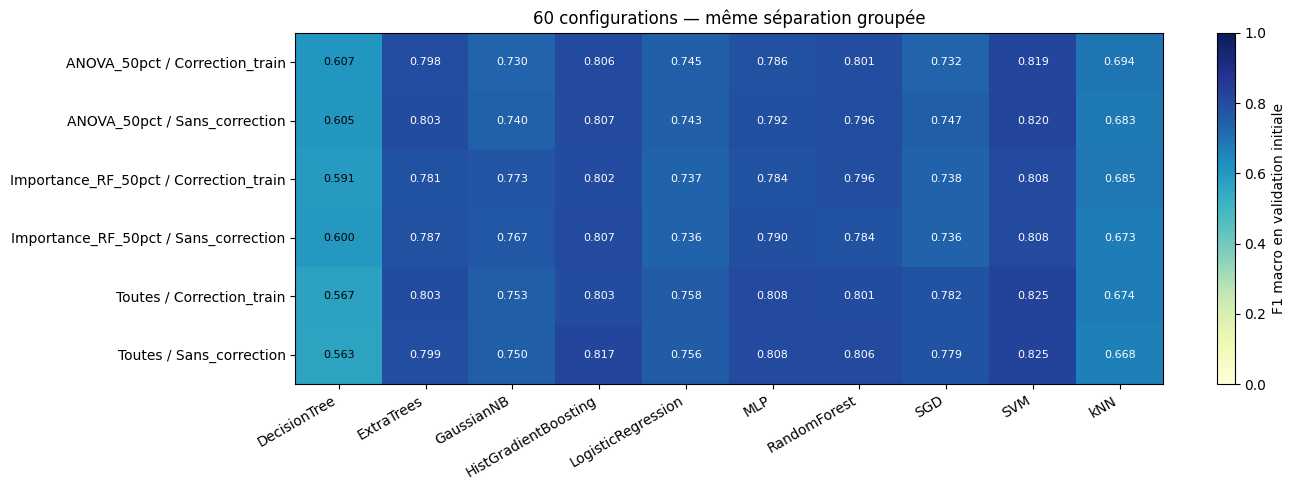

Le meilleur score de présélection est **0.8251** pour **SVM / Toutes / Sans_correction**. Le choix final tient ensuite compte de la recherche ciblée par groupes.

In [9]:
ranked = comparison.sort_values('validation_f1_macro', ascending=False, kind='stable').reset_index(drop=True)
ranked['ecart_f1_train_validation'] = ranked['train_f1_macro'] - ranked['validation_f1_macro']
display(ranked.round(4))
print('Référence majoritaire — F1 macro validation :', round(results['dummy_validation']['f1_macro'], 4))
baselines = pd.read_csv(OUT / 'baseline_results.csv')
display(baselines.round(4))
matrix = comparison.pivot(index=['selection', 'balancing'], columns='model', values='validation_f1_macro')
display(matrix.round(4))
fig, ax = plt.subplots(figsize=(14, 5))
image = ax.imshow(matrix.to_numpy(), cmap='YlGnBu', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=30, ha='right')
ax.set_yticks(range(len(matrix.index)), [f'{selection} / {balancing}' for selection, balancing in matrix.index])
for row_index in range(len(matrix.index)):
    for col_index in range(len(matrix.columns)):
        value = matrix.iloc[row_index, col_index]
        ax.text(col_index, row_index, f'{value:.3f}', ha='center', va='center',
                fontsize=8, color='white' if value > 0.65 else 'black')
fig.colorbar(image, ax=ax, label='F1 macro en validation initiale')
ax.set_title('60 configurations — même séparation groupée')
fig.tight_layout()
fig.savefig(OUT / 'figures/benchmark_60_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
screening_top = ranked.iloc[0]
display(Markdown(f"Le meilleur score de présélection est **{screening_top['validation_f1_macro']:.4f}** "
                 f"pour **{screening_top['model']} / {screening_top['selection']} / {screening_top['balancing']}**. "
                 'Le choix final tient ensuite compte de la recherche ciblée par groupes.'))

### 7.1. Effets de la correction, de la sélection et signes de surapprentissage

Nous calculons les différences de score entre correction et absence de correction pour chaque
couple modèle/sélection, puis entre sélection et variables complètes à stratégie identique.
Un delta positif indique une amélioration observée sur cette partition. Les comparaisons sont
appariées : mêmes données, modèle et paramètres de départ.

Un grand écart train/validation peut signaler le surapprentissage ou une différence de provenance.
Ces effets sont descriptifs ; une différence minime ne démontre pas une supériorité générale.

In [10]:
effect = comparison.pivot(index=['selection', 'model'], columns='balancing', values='validation_f1_macro')
effect['delta_correction'] = effect['Correction_train'] - effect['Sans_correction']
display(effect.round(4))
selection_effect = comparison.pivot(index=['model', 'balancing'], columns='selection', values='validation_f1_macro')
for method in ['ANOVA_50pct', 'Importance_RF_50pct']:
    selection_effect['delta_' + method] = selection_effect[method] - selection_effect['Toutes']
display(selection_effect.round(4))
improved = int((effect['delta_correction'] > 0).sum())
largest_gap = ranked.loc[ranked['ecart_f1_train_validation'].idxmax()]
display(Markdown(f"La correction améliore le F1 macro dans **{improved}/{len(effect)}** comparaisons appariées. "
                 f"L'écart train/validation maximal est **{largest_gap['ecart_f1_train_validation']:.4f}** "
                 f"pour **{largest_gap['model']} / {largest_gap['selection']} / {largest_gap['balancing']}**. "
                 'Les plis groupés et leurs supports permettent de compléter cette observation.'))

balancing                                 Correction_train  Sans_correction  \
selection           model                                                     
ANOVA_50pct         DecisionTree                    0.6068           0.6053   
                    ExtraTrees                      0.7978           0.8028   
                    GaussianNB                      0.7305           0.7397   
                    HistGradientBoosting            0.8060           0.8068   
                    LogisticRegression              0.7450           0.7433   
                    MLP                             0.7863           0.7919   
                    RandomForest                    0.8007           0.7957   
                    SGD                             0.7322           0.7467   
                    SVM                             0.8192           0.8202   
                    kNN                             0.6944           0.6831   
Importance_RF_50pct DecisionTree                    0.5914           0.5999   
                    ExtraTrees                      0.7806           0.7874   
                    GaussianNB                      0.7730           0.7668   
                    HistGradientBoosting            0.8020           0.8068   
                    LogisticRegression              0.7374           0.7362   
                    MLP                             0.7842           0.7896   
                    RandomForest                    0.7956           0.7842   
                    SGD                             0.7381           0.7361   
                    SVM                             0.8080           0.8080   
                    kNN                             0.6854           0.6734   
Toutes              DecisionTree                    0.5667           0.5627   
                    ExtraTrees                      0.8025           0.7988   
                    GaussianNB                      0.7530           0.7499   
                    HistGradientBoosting            0.8030           0.8168   
                    LogisticRegression              0.7579           0.7563   
                    MLP                             0.8083           0.8081   
                    RandomForest                    0.8011           0.8057   
                    SGD                             0.7824           0.7786   
                    SVM                             0.8251           0.8251   
                    kNN                             0.6742           0.6678   

balancing                                 delta_correction  
selection           model                                   
ANOVA_50pct         DecisionTree                    0.0015  
                    ExtraTrees                     -0.0050  
                    GaussianNB                     -0.0092  
                    HistGradientBoosting           -0.0008  
                    LogisticRegression              0.0017  
                    MLP                            -0.0056  
                    RandomForest                    0.0050  
                    SGD                            -0.0145  
                    SVM                            -0.0010  
                    kNN                             0.0113  
Importance_RF_50pct DecisionTree                   -0.0085  
                    ExtraTrees                     -0.0068  
                    GaussianNB                      0.0062  
                    HistGradientBoosting           -0.0049  
                    LogisticRegression              0.0012  
                    MLP                            -0.0054  
                    RandomForest                    0.0115  
                    SGD                             0.0019  
                    SVM                             0.0000  
                    kNN                             0.0121  
Toutes              DecisionTree                    0.0040  
                    ExtraTrees                      0.0037  
       

selection                              ANOVA_50pct  Importance_RF_50pct  \
model                balancing                                            
DecisionTree         Correction_train       0.6068               0.5914   
                     Sans_correction        0.6053               0.5999   
ExtraTrees           Correction_train       0.7978               0.7806   
                     Sans_correction        0.8028               0.7874   
GaussianNB           Correction_train       0.7305               0.7730   
                     Sans_correction        0.7397               0.7668   
HistGradientBoosting Correction_train       0.8060               0.8020   
                     Sans_correction        0.8068               0.8068   
LogisticRegression   Correction_train       0.7450               0.7374   
                     Sans_correction        0.7433               0.7362   
MLP                  Correction_train       0.7863               0.7842   
                     Sans_correction        0.7919               0.7896   
RandomForest         Correction_train       0.8007               0.7956   
                     Sans_correction        0.7957               0.7842   
SGD                  Correction_train       0.7322               0.7381   
                     Sans_correction        0.7467               0.7361   
SVM                  Correction_train       0.8192               0.8080   
                     Sans_correction        0.8202               0.8080   
kNN                  Correction_train       0.6944               0.6854   
                     Sans_correction        0.6831               0.6734   

selection                              Toutes  delta_ANOVA_50pct  \
model                balancing                                     
DecisionTree         Correction_train  0.5667             0.0401   
                     Sans_correction   0.5627             0.0426   
ExtraTrees           Correction_train  0.8025            -0.0047   
                     Sans_correction   0.7988             0.0040   
GaussianNB           Correction_train  0.7530            -0.0225   
                     Sans_correction   0.7499            -0.0102   
HistGradientBoosting Correction_train  0.8030             0.0030   
                     Sans_correction   0.8168            -0.0100   
LogisticRegression   Correction_train  0.7579            -0.0129   
                     Sans_correction   0.7563            -0.0130   
MLP                  Correction_train  0.8083            -0.0219   
                     Sans_correction   0.8081            -0.0162   
RandomForest         Correction_train  0.8011            -0.0004   
                     Sans_correction   0.8057            -0.0099   
SGD                  Correction_train  0.7824            -0.0503   
                     Sans_correction   0.7786            -0.0319   
SVM                  Correction_train  0.8251            -0.0059   
                     Sans_correction   0.8251            -0.0049   
kNN                  Correction_train  0.6742             0.0203   
                     Sans_correction   0.6678             0.0154   

selection                              delta_Importance_RF_50pct  
model                balancing                                    
DecisionTree         Correction_train                     0.0246  
                     Sans_correction                      0.0372  
ExtraTrees           Correction_train                    -0.0219  
                     Sans_correction                     -0.0114  
GaussianNB           Correction_train                     0.0200  
                     Sans_correction                      0.0169  
HistGradientBoosting Correction_train                    -0.0010  
                     Sans_correction                     -0.0099  
LogisticRegression   Correction_train                    -0.0205  
                     Sans_correction                     -0.0202  
MLP                  Correction_train           

La correction améliore le F1 macro dans **16/30** comparaisons appariées. L'écart train/validation maximal est **0.3856** pour **DecisionTree / Toutes / Sans_correction**. Les plis groupés et leurs supports permettent de compléter cette observation.

### 7.2. Temps de calcul et diagnostics de convergence

Un modèle utile ne se juge pas uniquement sur son meilleur score. La cellule présente les temps
du meilleur candidat initial de chaque modèle. Le benchmark partage un cache des prétraitements :
ses durées peuvent favoriser un candidat exécuté après un calcul partagé et ne constituent pas
un classement universel de vitesse. Le matériel, les versions et la charge influencent aussi les
mesures. L'extraction HOG/HSV est réalisée en amont des temps affichés.

Les alertes de convergence sont conservées avec le nombre d'itérations et leur message. Elles
peuvent signaler qu'un optimum n'a pas été atteint au budget choisi et limitent les conclusions
sur le modèle concerné. Elles ne doivent pas être masquées pour présenter un classement plus net.
Une comparaison performance/vitesse d'inférence sera présentée lors de l'évaluation finale.

In [11]:
best_per_family = ranked.drop_duplicates('model').copy()
display(best_per_family[['model', 'selection', 'balancing', 'n_features', 'validation_f1_macro',
                         'fit_seconds', 'validation_predict_seconds']].round(4))
print(results['timing_note'])
if 'convergence_warning' in comparison:
    flagged = comparison[comparison['convergence_warning'].fillna(False)]
    print('Candidats initiaux avec alerte de convergence :', len(flagged))
    if len(flagged):
        display(flagged[['model', 'selection', 'balancing', 'iterations', 'warnings']])

,model,selection,balancing,n_features,validation_f1_macro,fit_seconds,validation_predict_seconds
0,SVM,Toutes,Sans_correction,1860,0.8251,6.572,3.3836
4,HistGradientBoosting,Toutes,Sans_correction,1860,0.8168,53.101,0.0470
5,MLP,Toutes,Correction_train,1860,0.8083,4.680,0.0128
12,RandomForest,Toutes,Sans_correction,1860,0.8057,4.290,0.0578
14,ExtraTrees,ANOVA_50pct,Sans_correction,930,0.8028,1.200,0.0633
29,SGD,Toutes,Correction_train,1860,0.7824,6.745,0.0143
32,GaussianNB,Importance_RF_50pct,Correction_train,930,0.7730,0.311,0.0746
34,LogisticRegression,Toutes,Correction_train,1860,0.7579,0.906,0.0116
48,kNN,ANOVA_50pct,Correction_train,930,0.6944,0.374,0.0928
54,DecisionTree,ANOVA_50pct,Correction_train,930,0.6068,2.479,0.0119


Les temps de benchmark bénéficient d'un cache partagé des prétraitements ; ils décrivent cette exécution, pas un classement universel de vitesse. L'inférence est mesurée en batch, hors lecture d'image et extraction HOG/HSV.
Candidats initiaux avec alerte de convergence : 0


## 8. Recherche ciblée et validation croisée par groupes

Les trois modèles les mieux classées lors de la comparaison initiale font l'objet d'une petite
recherche de paramètres. Chaque candidat est ajusté et évalué sur les mêmes trois plis du
développement, en conservant les groupes indivisibles. Les transformations apprises et les
sélections sont réajustées dans chaque pli. Le **F1 macro moyen des plis** détermine le choix final.

### 8.1. Vérifier les supports avant d'interpréter les moyennes

Le développement ne contient que trois groupes de piétons, de tailles 531, 256 et 13.
Un des plis ne contient donc que très peu d'exemples de cette classe, même avec une
stratification par groupes.
Nous conservons cette limite visible plutôt que de couper les groupes pour obtenir un tableau
plus régulier. Le nombre d'images ne remplace pas le nombre de provenances indépendantes.

La cellule affiche les effectifs par classe dans chaque pli. Des supports faibles rendent le
rappel et le F1 de la classe sensibles à quelques erreurs. Les trois scores ne constituent pas
trois mesures indépendantes d'un modèle final entraîné sur toutes les données.

In [12]:
cv_folds = pd.read_csv(OUT / 'cv_folds.csv')
display(cv_folds.pivot(index='class', columns='fold', values='validation_count').reindex(CLASSES))
display(cv_folds)
minimum_support = int(cv_folds['validation_count'].min())
display(Markdown(f"Le support de validation minimal parmi les classes et les plis est de "
                 f"**{minimum_support} images**. Cette contrainte limite la précision des comparaisons."))

fold,1,2,3
class,,,
bus,266,267,267
car,266,267,267
cyclist,266,267,267
motorcycle,266,267,267
pedestrian,531,256,13


,fold,class,train_count,validation_count
0,1,bus,534,266
1,1,car,534,266
2,1,cyclist,534,266
3,1,motorcycle,534,266
4,1,pedestrian,269,531
5,2,bus,533,267
6,2,car,533,267
7,2,cyclist,533,267
8,2,motorcycle,533,267
9,2,pedestrian,544,256


Le support de validation minimal parmi les classes et les plis est de **13 images**. Cette contrainte limite la précision des comparaisons.

### 8.2. Comparer les paramètres et figer le modèle retenu

La cellule affiche les résultats de chaque candidat et les moyennes avec leur écart-type entre
plis. Cet écart-type décrit la sensibilité aux plis ; il n'est pas un intervalle de confiance.
La présélection a déjà consulté une partie de ces données de développement : les scores de cette
recherche restent des scores de sélection, susceptibles d'optimisme. Une validation imbriquée
de l'ensemble du processus demanderait davantage de groupes et de calcul.

Les configurations retenues sont enregistrées avant la nouvelle mesure sur le test.

In [13]:
cv_details = pd.read_csv(OUT / 'cross_validation_results.csv')
cv_summary = pd.read_csv(OUT / 'cv_summary.csv').sort_values('mean_f1_macro', ascending=False, kind='stable')
display(cv_summary.round(4))
display(cv_details.round(4))
winning_cv = cv_summary.loc[cv_summary['model'].eq(winner['model'])].iloc[0]
display(Markdown(f"**Modèle retenu : {winner['model']} / {winner['selection']} / {winner['balancing']}**. "
                 f"Son F1 macro moyen de sélection est **{winning_cv['mean_f1_macro']:.4f}**, avec un "
                 f"écart-type entre plis de **{winning_cv['std_f1_macro']:.4f}**. "
                 'Le choix reste celui-ci après consultation du test.'))
print('Paramètres retenus :', json.dumps(winner.get('parameters', {}), ensure_ascii=False, sort_keys=True))
print('Critère enregistré :', decision['criterion'])
print('Nombre de calculs de validation croisée :', len(cv_details))
print(results['cv_note'])

,model,selection,balancing,parameters,mean_f1_macro,std_f1_macro,mean_accuracy,n_folds,mean_fit_seconds,convergence_warnings
0,SVM,Toutes,Sans_correction,"{""C"": 10}",0.8345,0.0276,0.8500,3,5.4317,0
1,SVM,Toutes,Sans_correction,"{""C"": 30}",0.8345,0.0276,0.8500,3,5.5057,0
2,SVM,Toutes,Sans_correction,"{""C"": 1}",0.8211,0.0516,0.8449,3,4.9987,0
3,MLP,Toutes,Correction_train,"{""alpha"": 0.01}",0.8179,0.0159,0.8314,3,7.6573,0
4,MLP,Toutes,Correction_train,"{""alpha"": 0.001}",0.8177,0.0160,0.8314,3,6.6697,0
5,MLP,Toutes,Correction_train,"{""alpha"": 0.0001}",0.8175,0.0170,0.8311,3,5.7707,0
6,HistGradientBoosting,Toutes,Sans_correction,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 31}",0.8098,0.0498,0.8332,3,113.6843,0
7,HistGradientBoosting,Toutes,Sans_correction,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 15}",0.8065,0.0503,0.8298,3,72.1460,0
8,HistGradientBoosting,Toutes,Sans_correction,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 15}",0.8044,0.0517,0.8276,3,71.1503,0
9,HistGradientBoosting,Toutes,Sans_correction,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 31}",0.7959,0.0596,0.8223,3,122.0083,0


,selection,model,balancing,parameters,fold,validation_f1_macro,validation_accuracy,fit_seconds,fit_samples,convergence_warning,warnings,iterations,train_samples,validation_samples,validation_min_class_count
0,Toutes,SVM,Sans_correction,"{""C"": 1}",1,0.8611,0.8777,4.024,2405,False,NaN,1024,2405,1595,266
1,Toutes,SVM,Sans_correction,"{""C"": 1}",2,0.8392,0.8384,4.851,2676,False,NaN,976,2676,1324,256
2,Toutes,SVM,Sans_correction,"{""C"": 1}",3,0.7628,0.8187,6.121,2919,False,NaN,979,2919,1081,13
3,Toutes,SVM,Sans_correction,"{""C"": 10}",1,0.8590,0.8752,5.582,2405,False,NaN,1707,2405,1595,266
4,Toutes,SVM,Sans_correction,"{""C"": 10}",2,0.8398,0.8384,4.873,2676,False,NaN,1588,2676,1324,256
5,Toutes,SVM,Sans_correction,"{""C"": 10}",3,0.8046,0.8363,5.840,2919,False,NaN,1612,2919,1081,13
6,Toutes,SVM,Sans_correction,"{""C"": 30}",1,0.8590,0.8752,3.975,2405,False,NaN,1707,2405,1595,266
7,Toutes,SVM,Sans_correction,"{""C"": 30}",2,0.8398,0.8384,5.086,2676,False,NaN,1588,2676,1324,256
8,Toutes,SVM,Sans_correction,"{""C"": 30}",3,0.8046,0.8363,7.456,2919,False,NaN,1612,2919,1081,13
9,Toutes,HistGradientBoosting,Sans_correction,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 15}",1,0.8365,0.8508,69.531,2405,False,NaN,100,2405,1595,266


**Modèle retenu : SVM / Toutes / Sans_correction**. Son F1 macro moyen de sélection est **0.8345**, avec un écart-type entre plis de **0.0276**. Le choix reste celui-ci après consultation du test.

Paramètres retenus : {"C": 10}
Critère enregistré : cv_mean_f1_macro
Nombre de calculs de validation croisée : 30
La validation croisée règle les paramètres de trois familles présélectionnées sur une validation issue du même développement. Elle n'est pas imbriquée et ne fournit pas une estimation indépendante de généralisation.


## 9. Analyses complémentaires sur le développement

### 9.1. Ablation : formes, couleurs ou combinaison ?

Une étude d'ablation retire une partie de la représentation pour examiner son apport.
Nous comparons HOG seul, HSV seul et leur concaténation avec le même modèle de référence et
ses paramètres, sans sélection supplémentaire de variables, sur la séparation groupée initiale.
Ces résultats constituent un diagnostic
des descripteurs ; ils ne remplacent pas le protocole de choix final.

La cellule affiche le F1 macro, l'accuracy, la dimension et le temps d'ajustement. Un score
élevé obtenu avec la couleur seule pourrait notamment révéler une dépendance aux fonds ou
aux conditions de prise de vue ; il ne prouverait pas que la couleur identifie l'objet.

,descriptor,validation_f1_macro,validation_accuracy,n_features,fit_seconds,fit_samples,convergence_warning,warnings,iterations
0,HOG,0.8261,0.8401,1764,9.450,3262,False,NaN,2128
1,HSV,0.4141,0.4038,96,1.028,3262,False,NaN,5140
2,HOG_HSV,0.8251,0.8360,1860,5.987,3262,False,NaN,2032


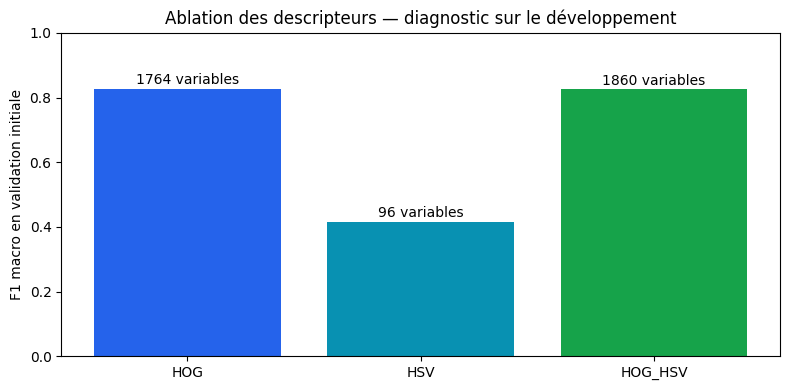

In [14]:
ablation = pd.read_csv(OUT / 'ablation_results.csv')
display(ablation.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ablation['descriptor'], ablation['validation_f1_macro'], color=['#2563eb', '#0891b2', '#16a34a'])
ax.set_ylim(0, 1)
ax.set_ylabel('F1 macro en validation initiale')
ax.set_title('Ablation des descripteurs — diagnostic sur le développement')
for position, (_, row) in enumerate(ablation.iterrows()):
    ax.text(position, row['validation_f1_macro'] + 0.015, f"{int(row['n_features'])} variables", ha='center')
fig.tight_layout()
fig.savefig(OUT / 'figures/descriptor_ablation.png', dpi=150, bbox_inches='tight')
plt.show()

### 9.2. Courbe d'apprentissage avec conservation des groupes

La courbe étudie l'effet de plusieurs volumes d'apprentissage, avec une validation initiale
fixe. Les sous-ensembles conservent les groupes indivisibles et les classes présentes.
Les effectifs réels peuvent s'écarter des fractions visées : un grand groupe ne peut pas
être divisé pour atteindre exactement un pourcentage.

L'écart entre F1 train et validation aide à discuter le surapprentissage et l'intérêt possible
de nouvelles données. Cette courbe ne démontre pas à elle seule que doubler le dataset apporterait
un gain précis : les sous-ensembles modifient aussi la composition en sources.
La cellule trace les scores en fonction des **effectifs réels**, plutôt que des fractions cibles.

,fraction,train_samples,min_class_count,train_accuracy,train_f1_macro,validation_accuracy,validation_precision_weighted,validation_recall_weighted,validation_f1_macro,validation_f1_weighted,validation_balanced_accuracy,validation_mcc,validation_predict_seconds,fit_seconds,fit_samples,convergence_warning,warnings,iterations
0,0.25,816,13,1.0,1.0,0.5623,0.7515,0.5623,0.5868,0.5182,0.6627,0.5210,0.8164,0.811,816,False,NaN,644
1,0.50,1631,13,1.0,1.0,0.5501,0.7714,0.5501,0.5737,0.4776,0.6688,0.5241,1.7683,2.139,1631,False,NaN,1223
2,0.75,2489,471,1.0,1.0,0.8469,0.8573,0.8469,0.8318,0.8500,0.8389,0.8048,2.2666,3.775,2489,False,NaN,1469
3,1.00,3262,544,1.0,1.0,0.8360,0.8539,0.8360,0.8251,0.8408,0.8346,0.7930,3.5541,6.217,3262,False,NaN,2032


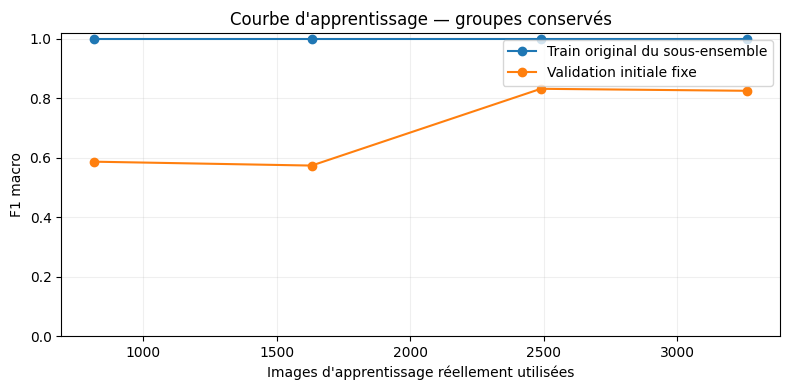

class,bus,car,cyclist,motorcycle,pedestrian
fraction,,,,,
0.25,209,190,197,207,13
0.50,419,408,391,400,13
0.75,491,486,497,471,544
1.00,680,680,681,677,544


Les effectifs par classe montrent que la courbe combine volume, équilibre et composition en groupes de provenance. Un saut de score après l'ajout d'un grand groupe ne mesure donc pas seulement l'effet du nombre d'images. Une légère baisse entre deux niveaux ne prouve pas non plus que davantage de données serait inutile.

In [15]:
learning = pd.read_csv(OUT / 'learning_curve.csv').sort_values('train_samples')
display(learning.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(learning['train_samples'], learning['train_f1_macro'], 'o-', label='Train original du sous-ensemble')
ax.plot(learning['train_samples'], learning['validation_f1_macro'], 'o-', label='Validation initiale fixe')
ax.set_ylim(0, 1.02)
ax.set_xlabel("Images d'apprentissage réellement utilisées")
ax.set_ylabel('F1 macro')
ax.set_title("Courbe d'apprentissage — groupes conservés")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'figures/learning_curve.png', dpi=150, bbox_inches='tight')
plt.show()

# Contrôler la composition, pas seulement le volume de chaque sous-ensemble.
from backend.livrable2 import grouped_learning_subsets
curve_records = manifest[manifest['split'].eq('train')].reset_index(drop=True)
curve_counts = []
for fraction, indices in grouped_learning_subsets(curve_records, seed=SEED):
    values = curve_records.iloc[indices]['class'].value_counts().reindex(CLASSES, fill_value=0)
    curve_counts.extend({'fraction': fraction, 'class': label, 'count': int(values[label])} for label in CLASSES)
curve_counts = pd.DataFrame(curve_counts)
curve_counts.to_csv(OUT / 'learning_curve_class_counts.csv', index=False)
display(curve_counts.pivot(index='fraction', columns='class', values='count').reindex(columns=CLASSES))
assert curve_counts.groupby('fraction')['count'].sum().tolist() == learning.sort_values('fraction')['train_samples'].tolist()
display(Markdown(
    "Les effectifs par classe montrent que la courbe combine volume, équilibre et composition "
    "en groupes de provenance. Un saut de score après l'ajout d'un grand groupe ne mesure donc "
    "pas seulement l'effet du nombre d'images. Une légère baisse entre deux niveaux ne prouve "
    "pas non plus que davantage de données serait inutile."
))


## 10. Évaluation finale des dix modèles

La meilleure configuration de chaque modèle a été figée avant la nouvelle évaluation du test.
Les trois modèles présélectionnés bénéficient de la recherche ciblée ; les autres conservent
leur meilleure configuration initiale. Les dix finalistes sont réajustés sur les 4 000 images
de développement : transformations, sélections et éventuels poids sont recalculés.
Ce budget d'optimisation différent doit être pris en compte dans la lecture du classement.

Le développement complet étant équilibré, les poids deviennent égaux et le suréchantillonnage
n'ajoute plus de lignes. Des modalités distinctes dans le train interne peuvent donc se rejoindre
lors de l'ajustement final. Les variables sélectionnées peuvent également changer.

Nous rapportons accuracy, précision, rappel et F1 pondérés, F1 macro et scores par classe.
La **balanced accuracy** est la moyenne des rappels par classe ; le **MCC multiclasses** complète
la lecture par une mesure de corrélation entre classes prédites et réelles.
Le modèle retenu reste celui choisi par validation croisée, quel que soit le classement test.

Le tableau de temps et le graphique final comparent les prédictions des dix modèles sur le
même lot d'images. Le temps par image est une moyenne en batch, hors lecture des fichiers et
extraction HOG/HSV ; il ne correspond donc pas à la latence complète d'une application.

,modele,retenu_par_cv,selection,correction,accuracy,precision_weighted,recall_weighted,f1_macro,f1_weighted,balanced_accuracy,mcc
0,SVM,True,Toutes,Sans_correction,0.819,0.8274,0.819,0.8178,0.8178,0.819,0.7762
9,MLP,False,Toutes,Correction_train,0.805,0.8094,0.805,0.8037,0.8037,0.805,0.7577
8,HistGradientBoosting,False,Toutes,Sans_correction,0.794,0.8038,0.794,0.7918,0.7918,0.794,0.7457
2,LogisticRegression,False,Toutes,Correction_train,0.769,0.7755,0.769,0.7679,0.7679,0.769,0.7132
1,SGD,False,Toutes,Correction_train,0.757,0.7671,0.757,0.7535,0.7535,0.757,0.6998
3,RandomForest,False,Toutes,Sans_correction,0.751,0.7592,0.751,0.7478,0.7478,0.751,0.6919
5,kNN,False,ANOVA_50pct,Correction_train,0.747,0.7512,0.747,0.7445,0.7445,0.747,0.6860
4,ExtraTrees,False,ANOVA_50pct,Sans_correction,0.735,0.7436,0.735,0.7312,0.7312,0.735,0.6721
7,GaussianNB,False,Importance_RF_50pct,Correction_train,0.715,0.7369,0.715,0.7079,0.7079,0.715,0.6504
6,DecisionTree,False,ANOVA_50pct,Correction_train,0.554,0.5522,0.554,0.5528,0.5528,0.554,0.4426


,precision,recall,f1-score,support
bus,0.9054,0.670,0.7701,200.0
car,0.7102,0.870,0.7820,200.0
cyclist,0.8109,0.815,0.8130,200.0
motorcycle,0.8177,0.785,0.8010,200.0
pedestrian,0.8925,0.955,0.9227,200.0


Le modèle retenu **SVM** obtient **81.90% d'accuracy** et **0.8178 de F1 macro** sur le test existant.

,model,n_features,fit_seconds,fit_samples,convergence_warning,warnings,iterations,test_predict_seconds,batch_ms_per_image
0,SVM,1860,10.040,4000,False,NaN,2410.0,4.3713,4.3713
1,SGD,1860,40.793,4000,False,NaN,1319.0,0.0376,0.0376
2,LogisticRegression,1860,2.831,4000,False,NaN,104.0,0.0439,0.0439
3,RandomForest,1860,11.078,4000,False,NaN,NaN,0.1227,0.1227
4,ExtraTrees,930,3.318,4000,False,NaN,NaN,0.1269,0.1269
5,kNN,930,0.565,4000,False,NaN,NaN,0.2299,0.2299
6,DecisionTree,930,5.870,4000,False,NaN,NaN,0.0329,0.0329
7,GaussianNB,930,6.247,4000,False,NaN,NaN,0.1694,0.1694
8,HistGradientBoosting,1860,126.493,4000,False,NaN,100.0,0.1257,0.1257
9,MLP,1860,7.066,4000,False,NaN,30.0,0.0294,0.0294


Les temps de benchmark bénéficient d'un cache partagé des prétraitements ; ils décrivent cette exécution, pas un classement universel de vitesse. L'inférence est mesurée en batch, hors lecture d'image et extraction HOG/HSV.


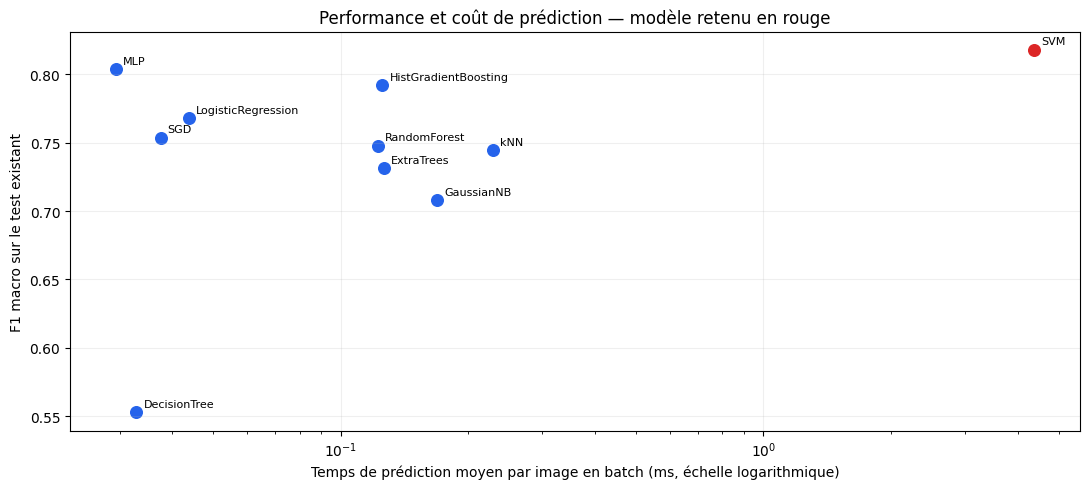

In [16]:
test_table = pd.DataFrame([
    {'modele': name, 'retenu_par_cv': name == winner['model'],
     'selection': scores['configuration']['selection'], 'correction': scores['configuration']['balancing'],
     **{metric: scores[metric] for metric in ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_macro', 'f1_weighted', 'balanced_accuracy', 'mcc']}}
    for name, scores in results['test'].items()
]).sort_values('f1_macro', ascending=False, kind='stable')
display(test_table.round(4))
selected_scores = results['test'][winner['model']]
per_class = pd.DataFrame(selected_scores['per_class']).T.reindex(CLASSES)
display(per_class.round(4))
display(Markdown(f"Le modèle retenu **{winner['model']}** obtient **{selected_scores['accuracy']:.2%} d'accuracy** "
                 f"et **{selected_scores['f1_macro']:.4f} de F1 macro** sur le test existant."))
if 'dummy_test' in results:
    print('Référence majoritaire — accuracy test :', round(results['dummy_test']['accuracy'], 4),
          '— F1 macro test :', round(results['dummy_test']['f1_macro'], 4))
final_timings = pd.read_csv(OUT / 'final_model_timings.csv')
display(final_timings.round(4))
print(results['timing_note'])
costs = test_table.merge(final_timings, left_on='modele', right_on='model')
fig, ax = plt.subplots(figsize=(11, 5))
for _, row in costs.iterrows():
    latency = max(float(row['batch_ms_per_image']), 0.001)
    ax.scatter(latency, row['f1_macro'], s=70,
               color='#dc2626' if row['retenu_par_cv'] else '#2563eb')
    ax.annotate(row['modele'], (latency, row['f1_macro']), xytext=(5, 4),
                textcoords='offset points', fontsize=8)
ax.set_xscale('log')
ax.set_xlabel('Temps de prédiction moyen par image en batch (ms, échelle logarithmique)')
ax.set_ylabel('F1 macro sur le test existant')
ax.set_title('Performance et coût de prédiction — modèle retenu en rouge')
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'figures/score_inference_cost.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.1. Incertitude descriptive par bootstrap de groupes

Rééchantillonner les images comme si elles étaient toutes indépendantes sous-estimerait le rôle
des ressemblances et des provenances. Nous rééchantillonnons donc les groupes d'évaluation du test
sur **1 000 tirages** et calculons des intervalles percentiles à 95 % sur les prédictions déjà produites. Certains groupes contiennent plusieurs classes : les tirer séparément par classe casserait ces liens.

Ces intervalles décrivent la sensibilité à la composition en groupes observés. Ils ne couvrent
pas les variations d'apprentissage, les choix de modèles, les étiquettes erronées ou un changement
de domaine. Les cinq classes sont fixées dans le calcul du F1 macro, y compris dans les
tirages sans certaines classes ; leur proportion est affichée. Il faut lire les intervalles
avec le nombre et la taille des groupes. Le chevauchement de deux
intervalles ne constitue pas un test formel de comparaison des modèles.

La cellule affiche tous les intervalles et un graphique limité aux familles de la recherche
ciblée pour garder la figure lisible. Le marqueur représente l'estimation sur le test complet.

,model,metric,estimate,lower_95,upper_95,bootstrap_groups,n_resamples,absent_class_fraction
0,SVM,accuracy,0.8190,0.7142,0.8888,586,1000,0.053
1,SVM,f1_macro,0.8178,0.6366,0.8774,586,1000,0.053
2,SGD,accuracy,0.7570,0.6449,0.8349,586,1000,0.053
3,SGD,f1_macro,0.7535,0.5789,0.8163,586,1000,0.053
4,LogisticRegression,accuracy,0.7690,0.6672,0.8387,586,1000,0.053
5,LogisticRegression,f1_macro,0.7679,0.5869,0.8236,586,1000,0.053
6,RandomForest,accuracy,0.7510,0.6317,0.8289,586,1000,0.053
7,RandomForest,f1_macro,0.7478,0.5793,0.8138,586,1000,0.053
8,ExtraTrees,accuracy,0.7350,0.6139,0.8192,586,1000,0.053
9,ExtraTrees,f1_macro,0.7312,0.5562,0.7980,586,1000,0.053


Part des tirages sans au moins une classe : 5.30%
Supports des groupes de piétons test : [45, 11, 144]
Intervalles percentile 95 % sur 1 000 tirages de groupes entiers, avec cinq classes fixes ; les tirages sans certaines classes sont inclus. Seulement trois groupes de piétons : interprétation exploratoire, sans conclusion de significativité statistique.


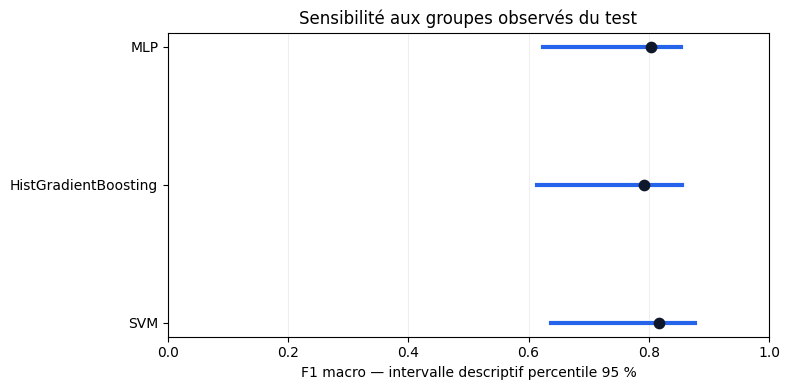

In [17]:
intervals = pd.read_csv(OUT / 'bootstrap_intervals.csv')
display(intervals.round(4))
print('Part des tirages sans au moins une classe :', f"{intervals['absent_class_fraction'].max():.2%}")
pedestrian_groups = manifest[manifest['split'].eq('test') & manifest['class'].eq('pedestrian')].groupby('evaluation_group').size()
print('Supports des groupes de piétons test :', pedestrian_groups.to_list())
print(results.get('bootstrap_note', 'Bootstrap par groupes sur le test existant.'))
top_cv_models = decision.get('top_cv_models', cv_summary['model'].drop_duplicates().head(3).tolist())
top_cv_models = [entry['model'] if isinstance(entry, dict) else entry for entry in top_cv_models]
focus = intervals[intervals['model'].isin(top_cv_models) & intervals['metric'].eq('f1_macro')].copy()
fig, ax = plt.subplots(figsize=(8, 4))
for position, (_, row) in enumerate(focus.iterrows()):
    ax.plot([row['lower_95'], row['upper_95']], [position, position], color='#2563eb', linewidth=3)
    ax.scatter(row['estimate'], position, s=55, color='#0f172a', zorder=3)
ax.set_yticks(range(len(focus)), focus['model'])
ax.set_xlim(0, 1)
ax.set_xlabel('F1 macro — intervalle descriptif percentile 95 %')
ax.set_title('Sensibilité aux groupes observés du test')
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / 'figures/bootstrap_finalists.png', dpi=150, bbox_inches='tight')
plt.show()

### 10.2. Matrices de confusion et erreurs visuelles

Chaque ligne représente la classe réelle, chaque colonne la classe prédite. La diagonale
contient les bonnes classifications. La cellule juxtapose les matrices des dix modèles pour
identifier leurs erreurs récurrentes, puis montre la matrice détaillée du modèle retenu et
jusqu'à six de ses erreurs. L'ordre des exemples est déterministe ; cet échantillon n'épuise
pas la diversité des cas difficiles.

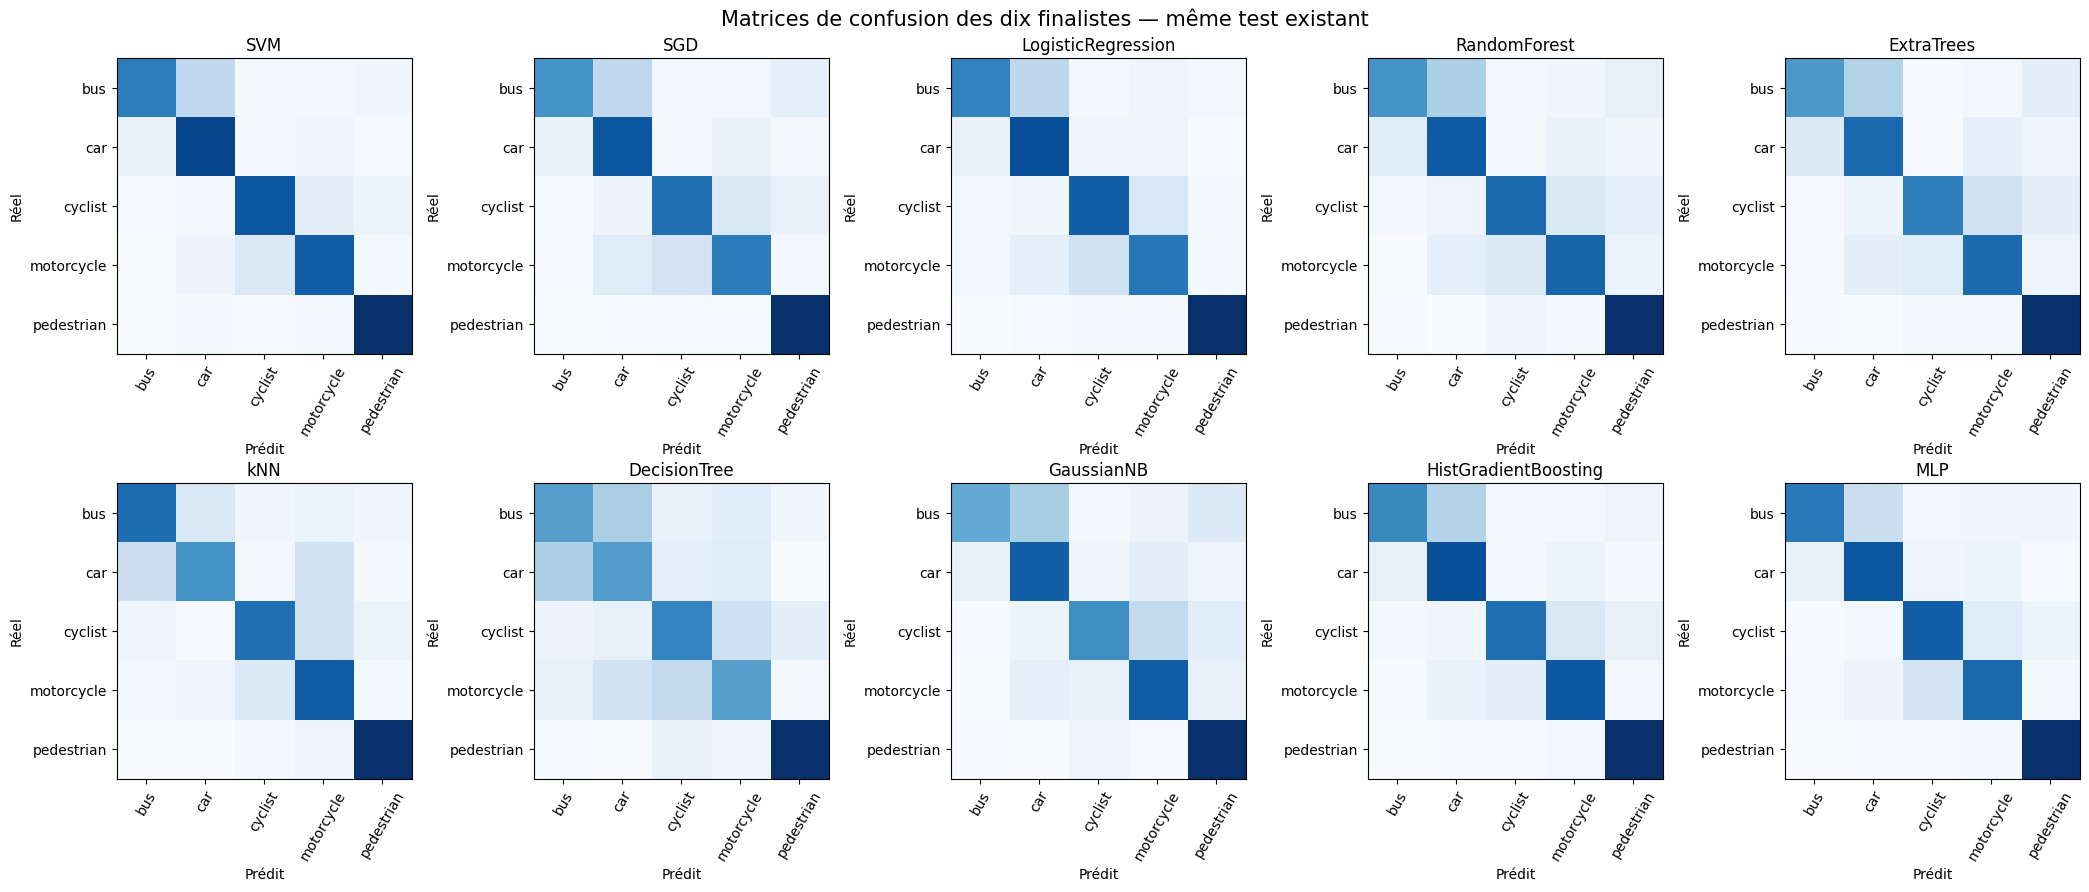

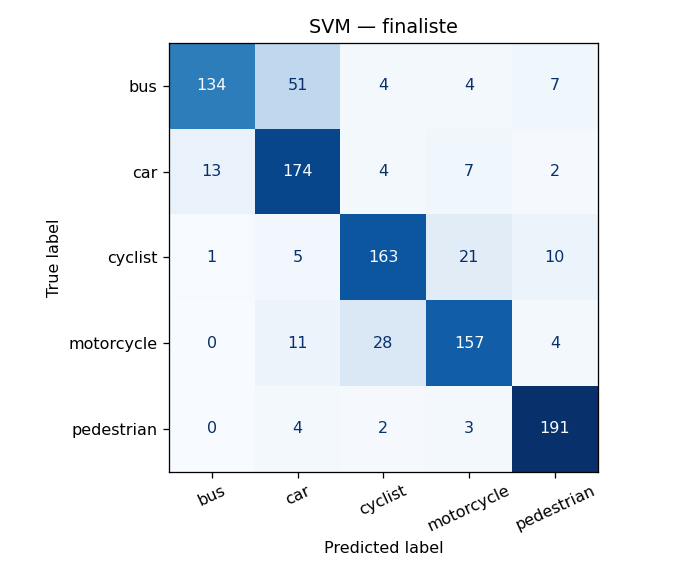

,classes,errors,a_to_b,b_to_a
0,"[bus, car]",64,51,13
1,"[cyclist, motorcycle]",49,21,28
2,"[car, motorcycle]",18,7,11
3,"[cyclist, pedestrian]",12,10,2
4,"[car, cyclist]",9,4,5


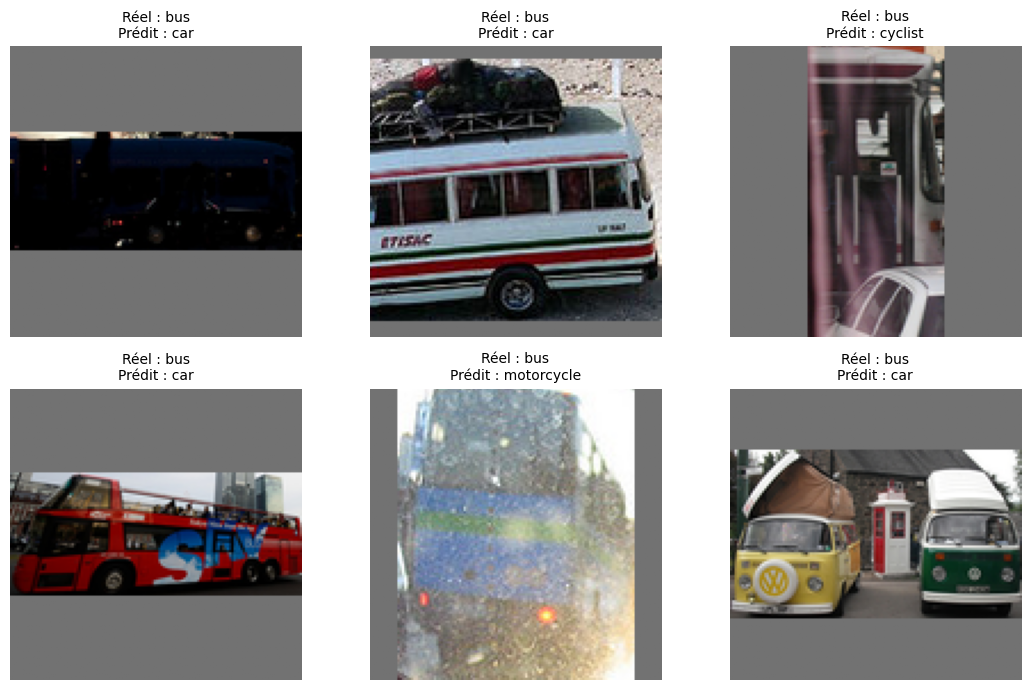

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(2, 5, figsize=(21, 9))
for ax, model in zip(axes.flat, results['test']):
    matrix = np.asarray(results['test'][model]['confusion_matrix'])
    ConfusionMatrixDisplay(matrix, display_labels=CLASSES).plot(
        ax=ax, cmap='Blues', colorbar=False, xticks_rotation=60, include_values=False)
    ax.set_title(model)
    ax.set_xlabel('Prédit')
    ax.set_ylabel('Réel')
fig.suptitle('Matrices de confusion des dix finalistes — même test existant', fontsize=15)
fig.tight_layout()
fig.savefig(OUT / 'figures/confusion_all_models.png', dpi=150, bbox_inches='tight')
plt.show()
display(DisplayImage(filename=str(OUT / f"figures/confusion_{winner['model']}.png")))
display(pd.DataFrame(selected_scores['most_confused_pairs']))
predictions = pd.read_csv(OUT / 'test_predictions.csv')
errors = predictions[predictions['class'].ne(predictions[winner['model']])].head(6)
if len(errors):
    fig, axes = plt.subplots(2, 3, figsize=(11, 7))
    for ax in axes.flat:
        ax.axis('off')
    for ax, (_, row) in zip(axes.flat, errors.iterrows()):
        ax.imshow(load_pixels(ROOT / 'dataset' / row['image']))
        ax.set_title(f"Réel : {row['class']}\nPrédit : {row[winner['model']]}", fontsize=10)
    fig.tight_layout()
    fig.savefig(OUT / 'figures/selected_errors.png', dpi=150, bbox_inches='tight')
    plt.show()

### 10.3. Discussion des erreurs et effets de provenance

Des silhouettes et roues proches peuvent expliquer des confusions vélo/moto ; le gabarit et les
fenêtres peuvent rapprocher voiture/bus. Une personne dominante dans le recadrage, une occultation
ou un arrière-plan atypique peuvent aussi tromper HOG/HSV. Ce sont des hypothèses visuelles,
pas des explications causales établies par les scores.

Le tableau décompose la performance du modèle retenu par source. Certaines sources ne contiennent
qu'une classe : leur accuracy et leurs supports sont plus faciles à interpréter que le F1 macro
calculé sur cinq classes globales. Un score sur une source connue n'établit pas la robustesse
à une provenance inconnue. Les exemples difficiles devraient guider une prochaine collecte
d'images et une revue des annotations, plutôt qu'un ajustement répété sur ce test.

In [19]:
source_rows = []
for source, scores in selected_scores['by_source'].items():
    support = {c: int(scores['per_class'][c]['support']) for c in CLASSES}
    source_rows.append({'source': source, 'images': sum(support.values()),
                        'classes_presentes': ', '.join(c for c, n in support.items() if n),
                        'accuracy': scores['accuracy'], 'f1_pondere': scores['f1_weighted']})
display(pd.DataFrame(source_rows).round(4))

,source,images,classes_presentes,accuracy,f1_pondere
0,coco,304,"bus, car, cyclist, motorcycle",0.7961,0.8105
1,kaggle,358,"bus, cyclist, motorcycle, pedestrian",0.8715,0.8863
2,original,194,"bus, car, cyclist, motorcycle",0.6443,0.6080
3,penn_fudan,144,pedestrian,0.9722,0.9859


## 11. Modèle sauvegardé et vérification de l'inférence

Le modèle retenu est exporté avec sa pipeline complète et la configuration HOG/HSV. La cellule
recharge cet artefact local et vérifie sur une image test déjà évaluée que la classe prédite
est identique à celle enregistrée. Ce contrôle vérifie l'export ; il ne mesure pas une nouvelle
généralisation. Une probabilité éventuellement disponible n'est pas automatiquement calibrée
et ne doit pas être interprétée comme une garantie de fiabilité sur la route.

In [20]:
import joblib
artifact = joblib.load(OUT / 'selected_pipeline.joblib')
row = predictions.iloc[0]
vector = extract_features(ROOT / 'dataset' / row['image'], artifact['feature_config'])[None, :]
label = artifact['pipeline'].predict(vector)[0]
assert label == row[winner['model']]
assert predictions[list(results['test'])].notna().all().all()
print('Modèle retenu :', winner['model'])
print('Image :', row['image'])
print('Classe réelle :', row['class'], '— prédiction après rechargement :', label)
print('Cohérence export / prédictions enregistrées : OK')

Modèle retenu : SVM
Image : test/bus/coco_1365288.png
Classe réelle : bus — prédiction après rechargement : bus
Cohérence export / prédictions enregistrées : OK


## 12. Synthèse pour la présentation et analyse critique

La synthèse reprend les résultats calculés à chaque étape : présélection, recherche ciblée,
évaluation du modèle retenu et diagnostics. Une augmentation du nombre de candidats rend la
comparaison plus riche mais augmente aussi le risque de choisir un score chanceusement élevé.
Le protocole, les comparaisons appariées et les limites sont donc aussi importants que le score.

La cellule génère un bilan sans présupposer qu'une sélection de variables ou une correction
du déséquilibre améliore tous les modèles. Les recommandations de collecte restent des
hypothèses à vérifier sur des images indépendantes.

In [21]:
selected_benchmark = comparison[(comparison['model'].eq(winner['model'])) &
                                (comparison['selection'].eq(winner['selection'])) &
                                (comparison['balancing'].eq(winner['balancing']))].iloc[0]
baseline = comparison[(comparison['model'].eq(winner['model'])) &
                      (comparison['selection'].eq('Toutes')) &
                      (comparison['balancing'].eq(winner['balancing']))].iloc[0]
selection_delta = float(selected_benchmark['validation_f1_macro'] - baseline['validation_f1_macro'])
hog_hsv = ablation.loc[ablation['descriptor'].eq('HOG_HSV')]
descriptor_best = ablation.sort_values('validation_f1_macro', ascending=False, kind='stable').iloc[0]
display(Markdown(
    f"**Étendue :** {comparison['model'].nunique()} modèles, {len(comparison)} configurations initiales "
    f"et {len(cv_details)} ajustements de validation croisée ciblée, plus les diagnostics.\n\n"
    f"**Choix final :** {winner['model']} / {winner['selection']} / {winner['balancing']}, "
    f"avec un F1 macro moyen de sélection de {winning_cv['mean_f1_macro']:.4f} "
    f"(écart-type entre plis {winning_cv['std_f1_macro']:.4f}).\n\n"
    f"**Résultat sur le test existant :** accuracy {selected_scores['accuracy']:.2%}, "
    f"F1 macro {selected_scores['f1_macro']:.4f}.\n\n"
    f"**Sélection des variables :** à paramètres initiaux identiques, l'écart avec les variables "
    f"complètes du même modèle et de la même stratégie est de {selection_delta:+.4f} en F1 macro. "
    'Cette comparaison concerne la présélection, avant le réglage ciblé des paramètres.\n\n'
    f"**Déséquilibre :** la correction améliore {improved}/{len(effect)} comparaisons appariées. "
    'Son intérêt dépend de la famille et de la représentation.\n\n'
    f"**Ablation :** {descriptor_best['descriptor']} obtient le meilleur F1 macro de ce diagnostic "
    f"({descriptor_best['validation_f1_macro']:.4f}). Ce résultat ne change pas le choix final."
))

**Étendue :** 10 modèles, 60 configurations initiales et 30 ajustements de validation croisée ciblée, plus les diagnostics.

**Choix final :** SVM / Toutes / Sans_correction, avec un F1 macro moyen de sélection de 0.8345 (écart-type entre plis 0.0276).

**Résultat sur le test existant :** accuracy 81.90%, F1 macro 0.8178.

**Sélection des variables :** à paramètres initiaux identiques, l'écart avec les variables complètes du même modèle et de la même stratégie est de +0.0000 en F1 macro. Cette comparaison concerne la présélection, avant le réglage ciblé des paramètres.

**Déséquilibre :** la correction améliore 16/30 comparaisons appariées. Son intérêt dépend de la famille et de la représentation.

**Ablation :** HOG obtient le meilleur F1 macro de ce diagnostic (0.8261). Ce résultat ne change pas le choix final.

### Ce que l'étude apporte au-delà du minimum demandé

- Une comparaison de dix modèles couvrant modèles linéaires, noyaux, arbres, ensembles,
  voisins, modèle probabiliste et réseau de neurones dense.
- Des comparaisons appariées de trois sélections et de deux traitements du déséquilibre.
- Une recherche ciblée avec validation croisée groupée et supports rendus visibles.
- Une analyse du temps de calcul, des descripteurs et du volume d'apprentissage.
- Une discussion des erreurs, des sources et de l'incertitude liée aux groupes du test.
- Une pipeline sauvegardée, des fichiers de traçabilité et une vérification de l'inférence.

### Limites à défendre devant le jury

1. **Peu de groupes indépendants de piétons :** les supports des plis sont inégaux, parfois faibles.
2. **Sélection réutilisant le développement :** présélection puis recherche ciblée ne constituent
   pas une validation imbriquée indépendante de l'ensemble de l'étude.
3. **Budget d'optimisation ciblé :** les trois modèles présélectionnés sont davantage réglés
   que les sept autres. Un résultat inférieur ici n'exclut pas leur potentiel avec un autre budget.
4. **Test déjà consulté :** les intervalles bootstrap ne lui rendent pas son indépendance historique.
5. **Qualité et domaine :** annotations non toutes revues, relations entre sources potentiellement
   inconnues, fonds et photos de produit susceptibles de créer des raccourcis visuels.
6. **Périmètre :** classification d'objets recadrés. Les résultats ne prouvent ni la détection
   de scènes complètes ni la fiabilité d'une application de conduite autonome.

### Suite du projet : priorités justifiées

1. Collecter davantage de groupes indépendants, particulièrement pour les piétons, et réserver
   à l'avance un nouveau test externe. Cela répond directement à la principale limite du protocole.
2. Mettre en place une validation imbriquée et un budget de réglage comparable si l'objectif
   devient une conclusion générale entre familles, plutôt qu'une étude exploratoire.
3. Revoir les annotations et enrichir les situations difficiles : vues, éclairages, occultations,
   personnes sur deux-roues et arrière-plans variés.
4. Étudier d'autres proportions de sélection et d'autres représentations sous le même protocole.
   Une éventuelle approche par transfert d'apprentissage devrait faire l'objet d'une comparaison
   séparée et d'une documentation de ses ressources et de ses données préalables.
5. Préparer une démonstration et mesurer le temps complet, de l'image à la prédiction.
   Les scènes de `demo_scenes/` partagent certaines sources avec train et ne constituent pas
   un jeu d'évaluation indépendant.

### Fichiers et reproduction

`backend/models/livrable2/` contient la comparaison large, la recherche ciblée et ses plis,
l'ablation, la courbe d'apprentissage, les intervalles bootstrap, les décisions figées,
l'audit et le manifeste, les variables retenues, les mesures détaillées, les prédictions,
les figures et le modèle local. Le notebook et les scripts partagent les mêmes fonctions.

**Commande de reproduction :** `python -m backend.livrable2` depuis la racine du projet.

## 13. Préparer la soutenance

**Pourquoi choisir le F1 macro ?** Il donne le même poids à chacune des cinq classes. La
validation groupée est déséquilibrée ; l'accuracy seule pourrait masquer une faiblesse sur une
classe. Nous affichons aussi les scores par classe, la balanced accuracy et le MCC.

**Pourquoi conserver les groupes de provenance ?** Deux images apparentées peuvent être très
semblables. Les répartir entre apprentissage et validation ferait paraître la généralisation
meilleure qu'elle ne l'est. Les groupes restent ensemble, même si les effectifs deviennent inégaux.

**Quelle différence entre HOG/HSV et la sélection des variables ?** HOG/HSV transforme une image
en 1 860 nombres selon une règle fixe. La sélection apprend ensuite sur le train quelles composantes
conserver. L'ablation compare les blocs formes/couleurs ; elle est distincte de la sélection.

**Pourquoi corriger un dataset initialement équilibré ?** La séparation par groupes crée un
déséquilibre dans le train interne. Nous comparons la correction à l'absence de correction ;
les résultats appariés montrent si elle aide selon le modèle et la sélection.

**Pourquoi une validation croisée ciblée sur trois modèles ?** La comparaison initiale couvre
60 configurations à budget raisonnable, puis la recherche cible les trois modèles présélectionnés.
Cela concentre le calcul, mais favorise leur budget de réglage. Comme la présélection consulte
le même développement, le score CV est un critère de choix et non une estimation indépendante.

**Est-ce que dix modèles garantissent un meilleur résultat ?** Non. Ils enrichissent la comparaison
et montrent les compromis, mais augmentent aussi les occasions de sélectionner un score chanceux.
Les conclusions reposent sur le protocole, les écarts mesurés et les limites, pas sur le seul nombre
d'algorithmes. Le test existant n'est pas utilisé pour remplacer le modèle choisi par CV.

**Quelle priorité pour confirmer le résultat ?** Recueillir des groupes indépendants, notamment
pour les piétons, puis évaluer une fois le choix figé sur un nouveau test externe. Les intervalles
bootstrap du test actuel ne remplacent pas cette confirmation.

## 14. Références méthodologiques

Les outils de cette étude s'appuient sur la documentation officielle de scikit-learn :

- [Apprentissage supervisé et familles de modèles](https://scikit-learn.org/stable/supervised_learning.html).
- [Validation croisée et séparations par groupes](https://scikit-learn.org/stable/modules/cross_validation.html).
- [Sélection des caractéristiques](https://scikit-learn.org/stable/modules/feature_selection.html).

Ces références décrivent les méthodes ; les performances présentées dans ce notebook sont
celles de nos exécutions sur nos images.